In [1]:
import pandas as pd
import glob

# Path to all CSVs (adjust this to your Kaggle download folder)
path = "./CICIDS2017/"  

# Load all CSV files into a list
all_files = glob.glob(path + "*.csv")

# Combine into one DataFrame
df_list = [pd.read_csv(file) for file in all_files]
df = pd.concat(df_list, ignore_index=True)
df.info()
df = df.sample(n=20000, random_state=42)

print("Combined shape:", df.shape)
print("Columns:", df.columns[:10], "...")
print("Unique labels:", df[' Label'].unique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2830743 entries, 0 to 2830742
Data columns (total 79 columns):
 #   Column                        Dtype  
---  ------                        -----  
 0    Destination Port             int64  
 1    Flow Duration                int64  
 2    Total Fwd Packets            int64  
 3    Total Backward Packets       int64  
 4   Total Length of Fwd Packets   int64  
 5    Total Length of Bwd Packets  int64  
 6    Fwd Packet Length Max        int64  
 7    Fwd Packet Length Min        int64  
 8    Fwd Packet Length Mean       float64
 9    Fwd Packet Length Std        float64
 10  Bwd Packet Length Max         int64  
 11   Bwd Packet Length Min        int64  
 12   Bwd Packet Length Mean       float64
 13   Bwd Packet Length Std        float64
 14  Flow Bytes/s                  float64
 15   Flow Packets/s               float64
 16   Flow IAT Mean                float64
 17   Flow IAT Std                 float64
 18   Flow IAT Max         

In [2]:
import numpy as np
import pennylane as qml
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE
from scipy.stats import mode
import time
import os
from joblib import dump, load
import os
from scipy.stats import mode
from tqdm import tqdm
from sklearn.decomposition import PCA
import torch
import torch.nn as nn
import torch.optim as optim


SEED = 42
NUM_FEATURES = 13

In [3]:
# df = df.replace([np.inf, -np.inf], np.nan)
# df = df.dropna()

# df.columns = df.columns.str.strip()

# # Custom binary encoding: BENIGN = 0, all attacks = 1
# def create_binary_labels(labels):
#     return (labels != 'BENIGN').astype(int)

# # Apply binary encoding
# y_binary = create_binary_labels(df['Label'])

# # Verify the encoding
# print("Original labels:", df['Label'].unique())
# print("Binary encoding:")
# print("BENIGN ->", y_binary[df['Label'] == 'BENIGN'].iloc[0])
# print("Attack samples ->", y_binary[df['Label'] != 'BENIGN'].unique())
# print("\nClass distribution:")
# print(f"Normal (0): {sum(y_binary == 0)}")
# print(f"Attack (1): {sum(y_binary == 1)}")

# # Use this instead of LabelEncoder for the target variable
# y = y_binary

In [4]:
df = df.replace([np.inf, -np.inf], np.nan)
df = df.dropna()

# Strip spaces from column names
df.columns = df.columns.str.strip()

# categorical_cols = df.select_dtypes(include='object').columns
# label_encoders = {}

# le = LabelEncoder()
# for col in categorical_cols:
#     df[col] = le.fit_transform(df[col].astype(str))
#     label_encoders[col] = le
#     print(f"\nColumn: {col}")
#     print(dict(zip(le.classes_, le.transform(le.classes_))))

# X = df.drop('Label', axis=1)   # note: 'Label' (no space after cleaning)
# y = df['Label']

df['Label'] = df['Label'].apply(lambda x: 0 if x.strip() == "BENIGN" else 1)

print("Unique labels after mapping:", df['Label'].unique())
print(df['Label'].value_counts())

feature_names = df.columns
# Separate features/labels
X = df.drop('Label', axis=1)
y = df['Label']


# Train/test split
SEED = 42
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEED)
print(f"Original class distribution (train): {np.bincount(y_train)}")

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=NUM_FEATURES, random_state=SEED)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test_scaled)

print("Features Selected: ")
for i, component in enumerate(pca.components_):
    important_idx = np.argmax(np.abs(component))
    print(f"Principal Component {i+1}: most important feature is '{feature_names[important_idx]}'")


X_train = X_train_pca
X_test = X_test_pca

print(X_train.shape, X_test.shape)

Unique labels after mapping: [0 1]
Label
0    16085
1     3893
Name: count, dtype: int64
Original class distribution (train): [12867  3115]
Features Selected: 
Principal Component 1: most important feature is 'Flow IAT Max'
Principal Component 2: most important feature is 'Total Backward Packets'
Principal Component 3: most important feature is 'Fwd IAT Min'
Principal Component 4: most important feature is 'Avg Fwd Segment Size'
Principal Component 5: most important feature is 'min_seg_size_forward'
Principal Component 6: most important feature is 'ACK Flag Count'
Principal Component 7: most important feature is 'Active Max'
Principal Component 8: most important feature is 'Fwd IAT Min'
Principal Component 9: most important feature is 'Active Mean'
Principal Component 10: most important feature is 'URG Flag Count'
Principal Component 11: most important feature is 'RST Flag Count'
Principal Component 12: most important feature is 'Fwd URG Flags'
Principal Component 13: most important fe

In [5]:
# from joblib import dump, load

# dump(scaler, 'scaler.joblib')
# dump(pca, 'pca.joblib')
# dump(label_encoders, 'label_encoders.joblib')
# dump(categorical_cols, 'categorical_cols.joblib')
# dump(feature_names, 'feature_names.joblib')

In [6]:
def create_sequential_batches(X_train, y_train, X_test, y_test, train_batch_size=300, test_batch_size=100):
    train_batches = []
    test_batches = []
    num_batches = min(len(X_train) // train_batch_size, len(X_test) // test_batch_size)
    for i in range(num_batches):
        train_start = i * train_batch_size
        train_end = train_start + train_batch_size
        test_start = i * test_batch_size
        test_end = test_start + test_batch_size
        train_batches.append((X_train[train_start:train_end], y_train[train_start:train_end]))
        test_batches.append((X_test[test_start:test_end], y_test[test_start:test_end]))
    return train_batches, test_batches

# Usage:
train_batches, test_batches = create_sequential_batches(X_train, y_train, X_test, y_test)

In [7]:
SEED = 42
# NUM_FEATURES = 4
TRAIN_BATCH_SIZE = 300
TEST_BATCH_SIZE = 100
NUM_BATCHES = 10

from joblib import Parallel, delayed


dev = qml.device("default.qubit", wires=NUM_FEATURES)

@qml.qnode(dev)
def kernel_circuit(x1, x2):
    qml.AngleEmbedding(x1, wires=range(NUM_FEATURES))
    qml.adjoint(qml.AngleEmbedding)(x2, wires=range(NUM_FEATURES))
    return qml.probs(wires=range(NUM_FEATURES))

def kernel(x1, x2):
    return kernel_circuit(x1, x2)

def compute_kernel_matrix(X1, X2):
    n_samples_1, n_samples_2 = len(X1), len(X2)
    kernel_matrix = np.zeros((n_samples_1, n_samples_2))
    for i in range(n_samples_1):
        for j in range(n_samples_2):
            probs = kernel_circuit(X1[i], X2[j])
            kernel_matrix[i, j] = probs[0]  # this represents the inner product now
    return kernel_matrix

In [8]:
from sklearn.model_selection import GridSearchCV

# Store metrics
all_test_preds = []
all_test_labels = []
train_accuracies = []
test_accuracies = []


for batch_idx in range(10):
    print(f"\nBatch {batch_idx + 1}/10")

    # Get batch data
    X_batch_train, y_batch_train = train_batches[batch_idx]
    X_batch_test, y_batch_test = test_batches[batch_idx]

    print("- Computing training kernel...")
    K_train = compute_kernel_matrix(X_batch_train, X_batch_train)

    print("- Computing testing kernel...")
    K_test = compute_kernel_matrix(X_batch_test, X_batch_train)

    if batch_idx == 4:
        K_train_4 = K_train
        K_test_4 = K_test

    # Hyperparameter tuning for C
    print("- Tuning C value...")
    param_grid = {"C": [0.1, 1, 10, 20, 30, 40, 50, 60]}
    grid = GridSearchCV(SVC(kernel='precomputed'), param_grid, cv=3)
    grid.fit(K_train, y_batch_train)
    best_model = grid.best_estimator_
    print(f"- Best C: {grid.best_params_['C']}")


    # Predictions
    y_pred = best_model.predict(K_test)
    all_test_preds.append(y_pred)
    all_test_labels.append(y_batch_test)

    # Overfitting check
    train_preds = best_model.predict(K_train)
    train_acc = accuracy_score(y_batch_train, train_preds)
    test_acc = accuracy_score(y_batch_test, y_pred)
    train_accuracies.append(train_acc)
    test_accuracies.append(test_acc)

    print(f"- Train Accuracy: {train_acc:.4f}")
    print(f"- Test Accuracy: {test_acc:.4f}")
    if train_acc - test_acc > 0.10:
        print("- Possible overfitting detected (Train >> Test)")



Batch 1/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 20
- Train Accuracy: 0.9600
- Test Accuracy: 0.9100

Batch 2/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 1
- Train Accuracy: 0.9667
- Test Accuracy: 0.8700

Batch 3/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9667
- Test Accuracy: 0.9100

Batch 4/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 40
- Train Accuracy: 0.9700
- Test Accuracy: 0.9300

Batch 5/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 50
- Train Accuracy: 0.9833
- Test Accuracy: 0.9000

Batch 6/10
- Computing training kernel...
- Computing testing kernel...
- Tuning C value...
- Best C: 10
- Train Accuracy: 0.9633
- Test Accuracy: 0.9100

Batch 7/10
- Computing training kernel...
- Computing testing kernel..

Text(0.5, 1.0, 'Quantum Kernel (4th) Train Matrix')

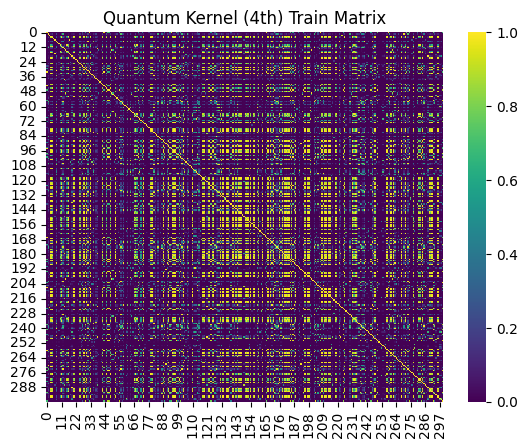

In [9]:
sns.heatmap(K_train_4, cmap="viridis")
plt.title("Quantum Kernel (4th) Train Matrix")

Text(0.5, 1.0, 'Quantum Kernel (10th) Train Matrix')

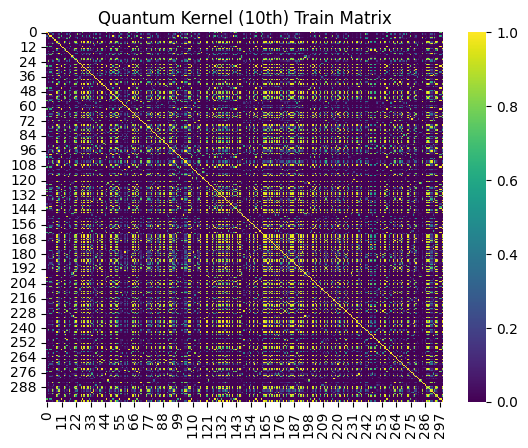

In [10]:
sns.heatmap(K_train, cmap="viridis")
plt.title("Quantum Kernel (10th) Train Matrix")

Text(0.5, 1.0, 'Quantum Kernel Test Matrix')

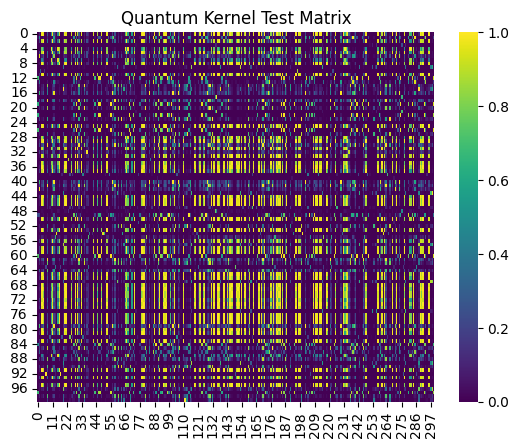

In [11]:
sns.heatmap(K_test_4, cmap="viridis")
plt.title("Quantum Kernel Test Matrix")

Text(0.5, 1.0, 'Quantum Kernel (10th) Test Matrix')

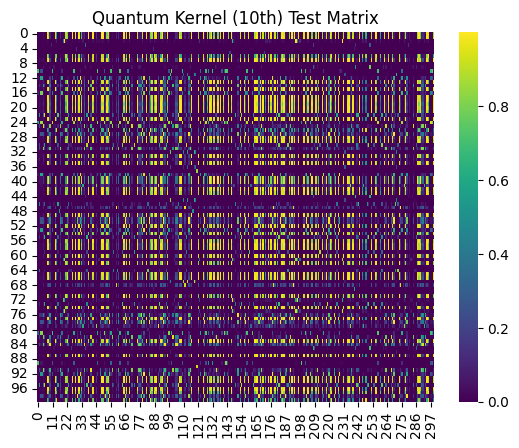

In [12]:
sns.heatmap(K_test, cmap="viridis")
plt.title("Quantum Kernel (10th) Test Matrix")

In [ ]:
# Final evaluation
# all_test_preds = np.concatenate(all_test_preds)
# all_test_labels = np.concatenate(all_test_labels)

final_acc = accuracy_score(all_test_labels, all_test_preds)
print(f"\nFinal Batched QSVM Accuracy: {final_acc:.4f}")
print("Classification Report:\n", classification_report(all_test_labels, all_test_preds))

# Confusion matrix
cm = confusion_matrix(all_test_labels, all_test_preds)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"], cbar=False, annot_kws={"size": 12})
# plt.title("Confusion Matrix - Ensemble QSVM")
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("True", fontsize=12)
plt.tight_layout()
plt.show()

# Plot train vs test accuracy
plt.plot(range(1, 11), train_accuracies, label="Train Accuracy", marker='o')
plt.plot(range(1, 11), test_accuracies, label="Test Accuracy", marker='s')
plt.title("Train vs Test Accuracy per Batch")
plt.xlabel("Batch #")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()



Final Batched QSVM Accuracy: 0.0000
Classification Report:
               precision    recall  f1-score   support

           0       0.00      0.00      0.00         0
           1       0.00      0.00      0.00         0
           2       1.00      1.00      1.00         1
           3       1.00      1.00      1.00         3
           4       0.50      0.50      0.50         2
           5       1.00      0.25      0.40         4
           6       0.75      1.00      0.86         3
           7       1.00      0.67      0.80         3
           8       0.00      0.00      0.00         1
           9       1.00      0.50      0.67         2
          10       0.75      1.00      0.86         3
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         1
          13       1.00      0.50      0.67         2
          14       0.50      1.00      0.67         1
          15       0.67      1.00      0.80         2
          16       0

/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/ritvik/Code/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: F-score is ill-defined and being set to 0.0 in labels with no true nor predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [15]:
from sklearn.metrics import f1_score

f1 = f1_score(all_test_labels, all_test_preds)

print(f"F1 Score QSVM: {f1:.4f}")

ValueError: Target is multilabel-indicator but average='binary'. Please choose another average setting, one of [None, 'micro', 'macro', 'weighted', 'samples'].

In [ ]:
from sklearn.metrics import average_precision_score, precision_recall_curve, auc

auprc_qsvm = average_precision_score(all_test_labels, all_test_preds)

print(f"AUPRC QSVM: {auprc_qsvm:.4f}")

AUPRC QSVM: 0.6081


Min FPR: 0.0
Max FPR: 1.0


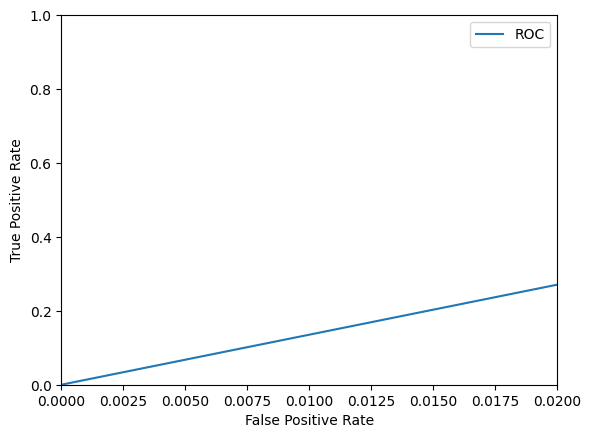

{'TPR@0.1%FPR': 0.013536672629695884, 'TPR@1.0%FPR': 0.13536672629695884}


In [ ]:
#def tpr_at_fpr(y_true, y_scores, target_fpr):
#    """Calculate TPR at a specific FPR threshold"""
#    fpr, tpr, thresholds = roc_curve(y_true, y_scores)
#    
#    # Find the index where FPR is closest to target_fpr
#    idx = np.argmin(np.abs(fpr - target_fpr))
#    
#    return tpr[idx], fpr[idx], thresholds[idx]


#tpr_001, actual_fpr_001, thresh_001 = tpr_at_fpr(all_test_labels, all_test_preds, 0.001)  # 0.1%
#tpr_01, actual_fpr_01, thresh_01 = tpr_at_fpr(all_test_labels, all_test_preds, 0.01)      # 1%

#print("TPR@FPR (0.1% and 1%)")
#print(f"TPR at 0.1% FPR: {tpr_001:.4f} (actual FPR: {actual_fpr_001:.4f}, threshold: {thresh_001:.4f})")
#print(f"TPR at 1% FPR: {tpr_01:.4f} (actual FPR: {actual_fpr_01:.4f}, threshold: {thresh_01:.4f})")


# def tpr_at_fpr_interp(fpr, tpr, target_fpr):
#     return np.interp(target_fpr, fpr, tpr)

# def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
#     fpr, tpr, _ = roc_curve(y_true, y_score)
#     print("Min FPR:", fpr.min())
#     print("Max FPR:", fpr.max())

#     results = {}
#     for target in fpr_targets:
#         idx = np.where(fpr <= target)[0]
#         results[f"TPR@{target*100:.1f}%FPR"] = tpr[idx[-1]] if len(idx) > 0 else 0.0
    
#     tpr_0_1 = tpr_at_fpr_interp(fpr, tpr, 0.001)  # 0.1%
#     tpr_1   = tpr_at_fpr_interp(fpr, tpr, 0.01)   # 1%

#     print("Interpolated TPR@0.1% FPR:", tpr_0_1)
#     print("Interpolated TPR@1% FPR:", tpr_1)

#     import matplotlib.pyplot as plt
#     plt.plot(fpr, tpr, label="ROC")
#     plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
#     plt.ylim(0, 1)
#     plt.xlabel("False Positive Rate")
#     plt.ylabel("True Positive Rate")
#     plt.legend()
#     plt.show()

    
#     return results

from sklearn.metrics import roc_curve
def compute_tpr_at_fpr(y_true, y_score, fpr_targets=[0.001, 0.01]):
    fpr, tpr, _ = roc_curve(y_true, y_score)
    print("Min FPR:", fpr.min())
    print("Max FPR:", fpr.max())

    results = {}
    for target in fpr_targets:
        # Always interpolate for robustness
        results[f"TPR@{target*100:.1f}%FPR"] = float(np.interp(target, fpr, tpr))

    # Plot zoomed-in ROC curve
    import matplotlib.pyplot as plt
    plt.plot(fpr, tpr, label="ROC")
    plt.xlim(0, 0.02)   # zoom in to 0–2% FPR
    plt.ylim(0, 1)
    plt.xlabel("False Positive Rate")
    plt.ylabel("True Positive Rate")
    plt.legend()
    plt.show()

    return results


# Example
metrics = compute_tpr_at_fpr(all_test_labels, all_test_preds)
print(metrics)


In [16]:
import numpy as np

def compute_kta(kernel_matrix, labels):
    """
    Compute Kernel Target Alignment (KTA).
    :param kernel_matrix: (n x n) kernel matrix (usually training)
    :param labels: (n,) label vector
    :return: alignment score (float)
    """
    # Convert labels to +1 / -1
    y = np.where(labels == 1, 1, -1)
    target_matrix = np.outer(y, y)

    # Frobenius inner product
    numerator = np.sum(kernel_matrix * target_matrix)
    denominator = np.linalg.norm(kernel_matrix, 'fro') * np.linalg.norm(target_matrix, 'fro')

    return numerator / denominator


In [1]:
n_layers = 5


def qnn_circuit(inputs, weights):
    qml.AngleEmbedding(inputs, wires=range(NUM_FEATURES))
    qml.StronglyEntanglingLayers(weights, wires=range(NUM_FEATURES))
    return [qml.expval(qml.PauliZ(i)) for i in range(NUM_FEATURES)]

qnode = qml.QNode(qnn_circuit, dev, interface="torch")

class QNNClassifier(nn.Module):
    def __init__(self, n_layers, n_qubits):
        super().__init__()
        weight_shapes = {"weights": (n_layers, n_qubits, 3)}
        self.qlayer = qml.qnn.TorchLayer(qnode, weight_shapes)
        self.fc = nn.Linear(n_qubits, 1)
    
    def forward(self, x):
        x = self.qlayer(x)
        x = self.fc(x)
        return x  # No sigmoid here

NameError: name 'qml' is not defined

In [ ]:
X_train_300 = X_train[:3000]
X_test_100 = X_test[:1000]
y_train_300 = y_train[:3000]
y_test_100 = y_test[:1000]

loss_values = []

# Prepare data
X_train_tensor = torch.tensor(X_train_300, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train_300.values, dtype=torch.float32).unsqueeze(1)
X_test_tensor = torch.tensor(X_test_100, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_100.values, dtype=torch.float32).unsqueeze(1)

# Use DataLoader for mini-batch training
from torch.utils.data import TensorDataset, DataLoader
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

# Model, loss, optimizer
model = QNNClassifier(n_layers=n_layers, n_qubits=NUM_FEATURES)
criterion = nn.BCEWithLogitsLoss()
optimizer = optim.Adam(model.parameters(), lr=0.01)
print(model.parameters())

# Training loop
epochs = 100
for epoch in range(epochs):
    model.train()
    running_loss = 0.0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()
    epoch_loss = running_loss / len(train_loader)
    loss_values.append(epoch_loss)
    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Evaluation
model.eval()
# with torch.no_grad():
#     y_pred_logits = model(X_test_tensor)
#     qnn_preds = (torch.sigmoid(y_pred_logits) > 0.5).int().squeeze().numpy()

with torch.no_grad():
    y_pred_logits = model(X_test_tensor)  # shape: (N, 1)
    qnn_sigmoid = torch.sigmoid(y_pred_logits).squeeze()  # shape: (N,)
    qnn_preds = (qnn_sigmoid > 0.5).int().numpy()

    # Convert to probability distribution over 2 classes: [P(class 0), P(class 1)]
    qnn_probs = torch.stack([1 - qnn_sigmoid, qnn_sigmoid], dim=1).cpu().numpy()  # shape: (N, 2)


accuracy_qnn = accuracy_score(y_test_100, qnn_preds)
print(f"QNN Accuracy on Test Data: {accuracy_qnn:.4f}")

print("Classification Report:\n", classification_report(y_test_100, qnn_preds))

cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"], cbar=False, annot_kws={"size": 12})
# plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("True", fontsize=12)
plt.tight_layout()
plt.show()

<generator object Module.parameters at 0x7f54a76fc740>


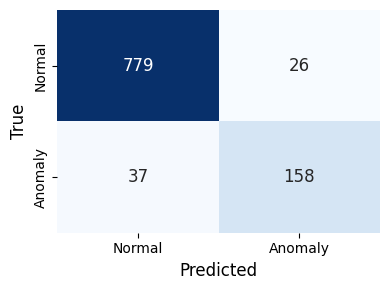

In [ ]:
cm = confusion_matrix(y_test_100, qnn_preds)
plt.figure(figsize=(4, 3))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=["Normal", "Anomaly"], yticklabels=["Normal", "Anomaly"], cbar=False, annot_kws={"size": 12})
# plt.title("Confusion Matrix - QNN")
plt.xlabel("Predicted", fontsize=12)
plt.ylabel("True", fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
f2 = f1_score(y_test_tensor, qnn_preds)

print(f"F1 score QNN: {f2:.4f}")

F1 score QNN: 0.8338


In [ ]:
auprc_qsvm = average_precision_score(y_test_tensor, qnn_preds)

print(f"AUPRC QNN: {auprc_qsvm:.4f}")

AUPRC QNN: 0.7328


Min FPR: 0.0
Max FPR: 1.0


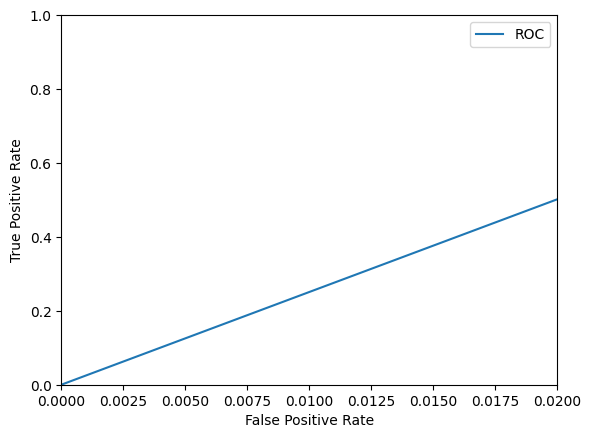

{'TPR@0.1%FPR': 0.025086785009861935, 'TPR@1.0%FPR': 0.25086785009861934}


In [ ]:
metrics = compute_tpr_at_fpr(y_test_tensor, qnn_preds)
print(metrics)

In [ ]:
from joblib import dump, load

dump(model, 'final_model(13  qnn).joblib')



['final_model(13  qnn).joblib']

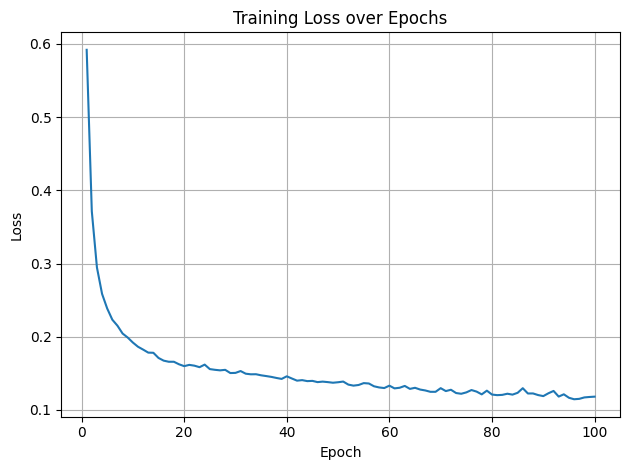

In [ ]:
plt.plot(range(1, epochs + 1), loss_values, label="Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss over Epochs")
plt.grid(True)
plt.tight_layout()
plt.show()

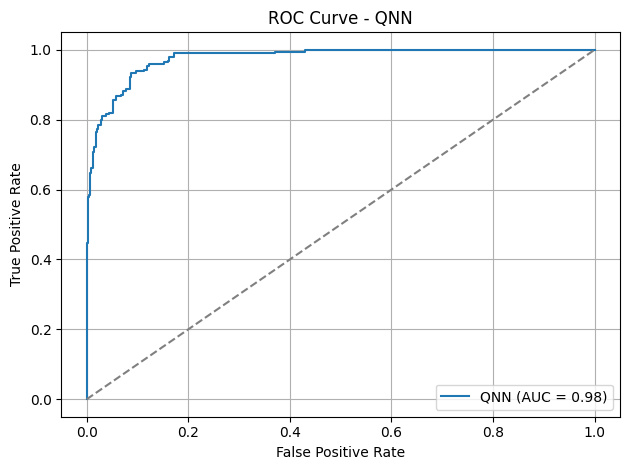

In [ ]:
from sklearn.metrics import roc_curve, auc

fpr, tpr, _ = roc_curve(y_test_100, qnn_sigmoid.numpy())
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f'QNN (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - QNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
qnn_model = model

In [ ]:
qsvm_preds = all_test_preds
X_meta = np.vstack([qsvm_preds, qnn_preds]).T  # shape: (n_samples, 2)
from sklearn.ensemble import RandomForestClassifier

# Initialize and train the meta-model
meta_model_rf = RandomForestClassifier(n_estimators=100, random_state=42)
meta_model_rf.fit(X_meta, y_test[:1000])  # match y_test slicing
ensemble_rf_preds = meta_model_rf.predict(X_meta)

print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))


Random Forest Meta-Model Accuracy: 0.937

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.86      0.81      0.83       195

    accuracy                           0.94      1000
   macro avg       0.91      0.89      0.90      1000
weighted avg       0.94      0.94      0.94      1000



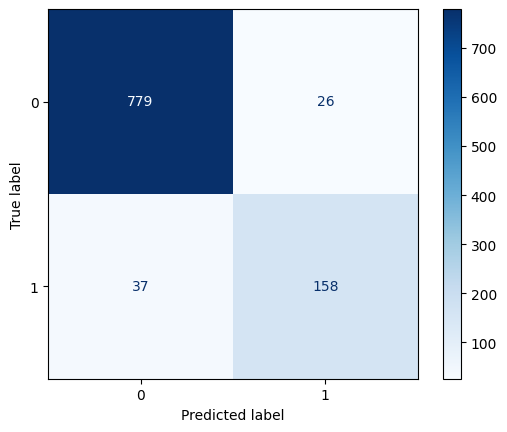

In [ ]:
# CM for RFMM

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Compute confusion matrix
cm = confusion_matrix(y_test[:1000], ensemble_rf_preds)


# Display
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues", values_format="d")
# plt.title("Confusion Matrix - Random Forest Meta Model")
plt.show()

In [ ]:
f3 = f1_score(y_test[:1000], ensemble_rf_preds)

print(f"F1 score RF Ensemble: {f3:.4f}")

F1 score RF Ensemble: 0.8338


In [ ]:
auprc_rf = average_precision_score(y_test[:1000], ensemble_rf_preds)

print(f"AUPRC RF Ensemble: {auprc_rf:.4f}")

AUPRC RF Ensemble: 0.7328


Min FPR: 0.0
Max FPR: 1.0


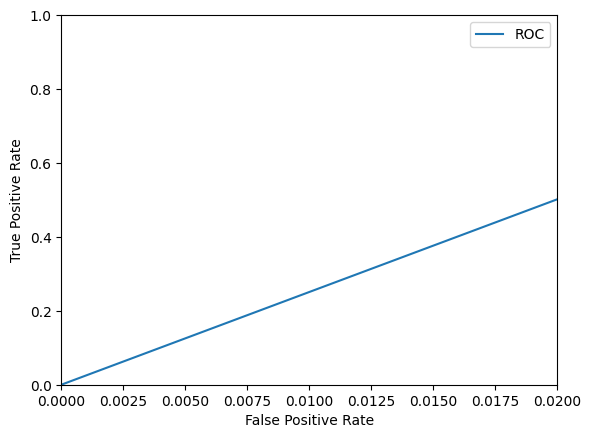

{'TPR@0.1%FPR': 0.025086785009861935, 'TPR@1.0%FPR': 0.25086785009861934}


In [ ]:
metrics = compute_tpr_at_fpr(y_test[:1000], ensemble_rf_preds)
print(metrics)

In [ ]:
from joblib import dump, load

dump(meta_model_rf, 'final_model(13).joblib')



['final_model(13).joblib']

In [ ]:
model = load('final_model(13).joblib')
ensemble_rf_preds = model.predict(X_meta)
print("Random Forest Meta-Model Accuracy:", accuracy_score(y_test[:1000], ensemble_rf_preds))
print("\nClassification Report (Random Forest Meta-Model):")
print(classification_report(y_test[:1000], ensemble_rf_preds))

Random Forest Meta-Model Accuracy: 0.937

Classification Report (Random Forest Meta-Model):
              precision    recall  f1-score   support

           0       0.95      0.97      0.96       805
           1       0.86      0.81      0.83       195

    accuracy                           0.94      1000
   macro avg       0.91      0.89      0.90      1000
weighted avg       0.94      0.94      0.94      1000



In [ ]:
# full_model = {
#     "qsvm": grid,                  
#     "qnn": qnn_model,              
#     "meta_model": meta_model_rf,      
#     "label_encoders": label_encoders, 
#     "scaler": scaler,                 
#     "pca": pca,
#     "feature_columns": list(feature_names)  
# }

# import joblib
# joblib.dump(full_model, "quantum_meta_model.joblib")


In [ ]:
from ptflops import get_model_complexity_info
import torch

# FLOPs for QNN
dummy_input = torch.rand(1, X_train.shape[1])  # 1 sample with correct feature size
flops, params = get_model_complexity_info(qnn_model, (X_train.shape[1],), verbose=False)

print(f"QNN FLOPs: {flops}, Params: {params}")


QNNClassifier(
  11, 6.832% Params, 11.0 Mac, 100.000% MACs, 
  (qlayer): <Quantum Torch Layer: func=qnn_circuit>
  (fc): Linear(11, 6.832% Params, 11.0 Mac, 100.000% MACs, in_features=10, out_features=1, bias=True)
)
QNN FLOPs: 11 Mac, Params: 161


In [ ]:
def estimate_rf_flops(model, num_features, num_samples):
    """
    Rough estimate FLOPs for Random Forest:
    - Each decision tree: O(depth * num_samples)
    - Multiply by number of trees
    """
    avg_depth = sum(estimator.tree_.max_depth for estimator in model.estimators_) / len(model.estimators_)
    flops = len(model.estimators_) * avg_depth * num_samples * num_features
    return flops

rf_flops = estimate_rf_flops(meta_model_rf, num_features=2, num_samples=len(X_test))  # 2 features = QSVM+QNN outputs
print(f"Estimated RF FLOPs: {rf_flops}")


Estimated RF FLOPs: 1598400.0


In [ ]:
def estimate_qsvm_flops(num_features, num_samples, num_batches):
    """
    Approx FLOPs for QSVM = O(N^2 * feature_map_cost)
    - num_features: features in each input vector
    - num_samples: number of training samples per batch
    - num_batches: number of batches QSVM was trained on
    """
    # Rough estimate: each kernel evaluation ~ O(num_features^2)
    feature_map_cost = num_features ** 2
    per_batch_flops = (num_samples ** 2) * feature_map_cost
    total_flops = num_batches * per_batch_flops
    return total_flops

# Example usage with your dataset
qsvm_flops = estimate_qsvm_flops(X_train.shape[1], len(X_train)//10, 10)  # since 10 batches
print(f"Estimated QSVM FLOPs: {qsvm_flops}")


Estimated QSVM FLOPs: 2553604000


In [ ]:
from sklearn.model_selection import learning_curve
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams.update({'font.size': 12})
# Generate learning curve for Random Forest meta-model
def plot_learning_curve(estimator, X, y, title="Learning Curve", cv=5, 
                       train_sizes=np.linspace(0.1, 1.0, 10)):
    """
    Generate and plot learning curve for a model
    """
    train_sizes, train_scores, val_scores = learning_curve(
        estimator, X, y, cv=cv, train_sizes=train_sizes, 
        scoring='accuracy', n_jobs=-1, random_state=42
    )
    
    # Calculate mean and std
    train_mean = np.mean(train_scores, axis=1)
    train_std = np.std(train_scores, axis=1)
    val_mean = np.mean(val_scores, axis=1)
    val_std = np.std(val_scores, axis=1)
    
    # Plot learning curve
    # plt.figure(figsize=(10, 6))
    plt.figure(figsize=(8, 5))
    plt.plot(train_sizes, train_mean, 'o-', color='blue', label='Training Score')
    plt.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
                     alpha=0.1, color='blue')
    
    plt.plot(train_sizes, val_mean, 'o-', color='red', label='Validation Score')
    plt.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
                     alpha=0.1, color='red')
    
    plt.xlabel('Training Set Size')
    plt.ylabel('Accuracy Score')
    plt.title(title)
    plt.legend(loc='best')
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    # Print final scores
    print(f"Final Training Score: {train_mean[-1]:.4f} (±{train_std[-1]:.4f})")
    print(f"Final Validation Score: {val_mean[-1]:.4f} (±{val_std[-1]:.4f})")
    
    return train_sizes, train_scores, val_scores

# Plot learning curve for Random Forest meta-model
train_sizes, train_scores, val_scores = plot_learning_curve(
    meta_model_rf, X_meta, y_test[:1000], 
    title="Learning Curve - Random Forest Meta-Model",
    cv=5
)

# Additional analysis: Check for overfitting/underfitting
final_train_mean = np.mean(train_scores, axis=1)[-1]
final_val_mean = np.mean(val_scores, axis=1)[-1]
gap = final_train_mean - final_val_mean

print(f"\nModel Analysis:")
if gap > 0.05:
    print(f"Potential overfitting detected (gap: {gap:.4f})")
elif final_val_mean < 0.7:
    print(f"Potential underfitting detected (validation score: {final_val_mean:.4f})")
else:
    print(f"Model appears well-balanced (gap: {gap:.4f})")

NameError: name 'meta_model_rf' is not defined

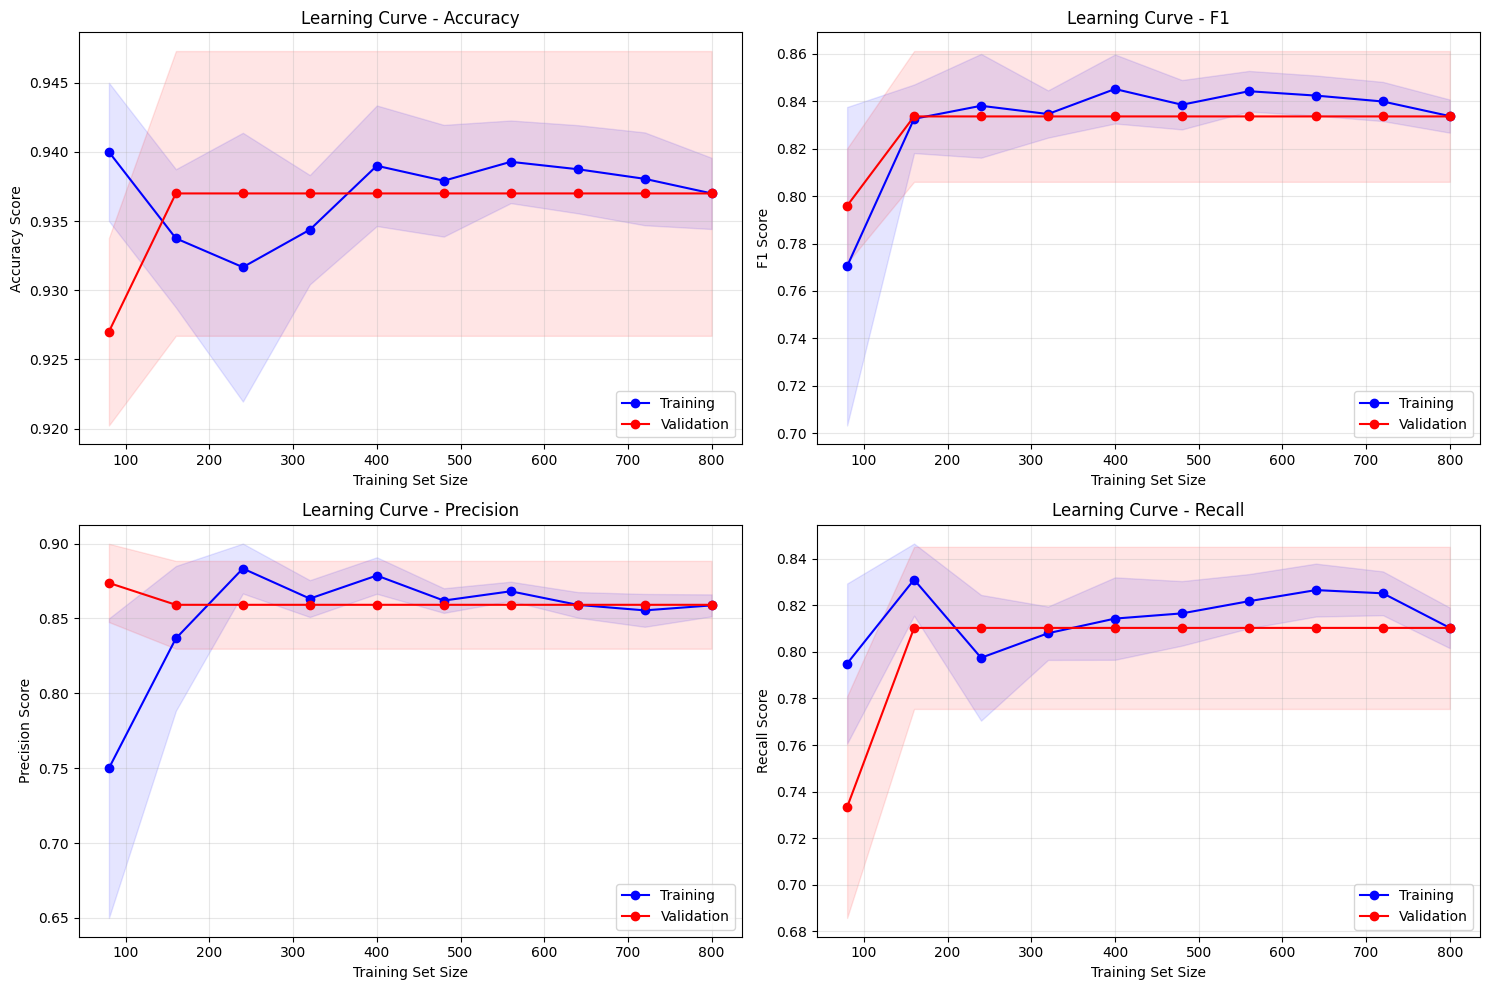

In [ ]:
from sklearn.model_selection import learning_curve
from sklearn.metrics import f1_score, precision_score, recall_score

# Multi-metric learning curve
def plot_multi_metric_learning_curve(estimator, X, y, cv=5):
    """
    Plot learning curves for multiple metrics
    """
    metrics = ['accuracy', 'f1', 'precision', 'recall']
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    axes = axes.ravel()
    
    for i, metric in enumerate(metrics):
        train_sizes, train_scores, val_scores = learning_curve(
            estimator, X, y, cv=cv, scoring=metric, 
            train_sizes=np.linspace(0.1, 1.0, 10), n_jobs=-1, random_state=42
        )
        
        train_mean = np.mean(train_scores, axis=1)
        train_std = np.std(train_scores, axis=1)
        val_mean = np.mean(val_scores, axis=1)
        val_std = np.std(val_scores, axis=1)
        
        axes[i].plot(train_sizes, train_mean, 'o-', color='blue', label='Training')
        axes[i].fill_between(train_sizes, train_mean - train_std, train_mean + train_std, 
                           alpha=0.1, color='blue')
        
        axes[i].plot(train_sizes, val_mean, 'o-', color='red', label='Validation')
        axes[i].fill_between(train_sizes, val_mean - val_std, val_mean + val_std, 
                           alpha=0.1, color='red')
        
        axes[i].set_xlabel('Training Set Size')
        axes[i].set_ylabel(f'{metric.capitalize()} Score')
        axes[i].set_title(f'Learning Curve - {metric.capitalize()}')
        axes[i].legend()
        axes[i].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.show()

# Plot multi-metric learning curve
plot_multi_metric_learning_curve(meta_model_rf, X_meta, y_test[:1000])

In [ ]:
qsvm_preds = np.array(qsvm_preds)
qnn_preds = np.array(qnn_preds)

# Disagreement rate (0.5 threshold is already implicit since you used hard labels)
disagreement_rate = np.mean(qsvm_preds != qnn_preds)

print("Disagreement Rate:", disagreement_rate)

Disagreement Rate: 0.056


In [ ]:
# True labels
y_true = y_test[:1000]

# Error indices
E_qsvm = np.where(qsvm_preds != y_true)[0]
E_qnn  = np.where(qnn_preds != y_true)[0]
E_int  = np.intersect1d(E_qsvm, E_qnn)

print("Errors - QSVM:", len(E_qsvm))
print("Errors - QNN :", len(E_qnn))
print("Errors - Both:", len(E_int))

Errors - QSVM: 97
Errors - QNN : 63
Errors - Both: 52


In [ ]:
# True labels
y_true = y_test[:1000]

# Error indices
E_qsvm = np.where(qsvm_preds != y_true)[0]
E_qnn  = np.where(qnn_preds != y_true)[0]
E_int  = np.intersect1d(E_qsvm, E_qnn)

print("Errors - QSVM:", len(E_qsvm))
print("Errors - QNN :", len(E_qnn))
print("Errors - Both:", len(E_int))

Errors - QSVM: 97
Errors - QNN : 63
Errors - Both: 52


In [ ]:
# Make sure predictions and labels are numpy arrays
ensemble_preds = np.array(ensemble_rf_preds)
y_true = np.array(y_test[:1000])

# Union of errors
E_union = np.union1d(E_qsvm, E_qnn)

# Recovery calculation
recovered = np.sum(ensemble_preds[E_union] == y_true[E_union])
ensemble_recovery_pct = recovered / len(E_union) * 100

print("Ensemble Recovery %:", ensemble_recovery_pct)


Ensemble Recovery %: 41.66666666666667


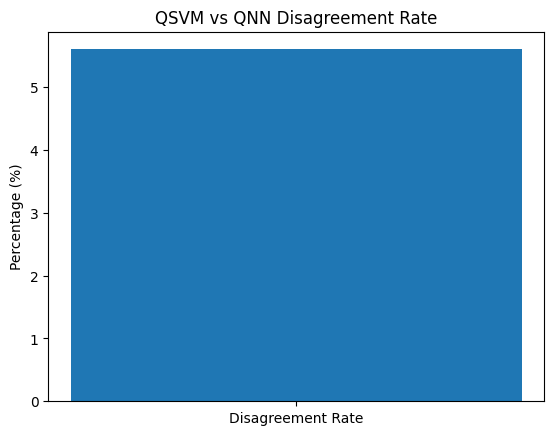

In [ ]:
plt.bar(["Disagreement Rate"], [disagreement_rate * 100])
plt.ylabel("Percentage (%)")
plt.title("QSVM vs QNN Disagreement Rate")
plt.show()

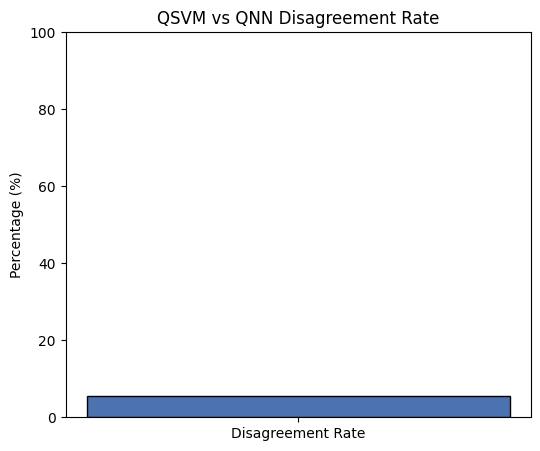

In [ ]:
import matplotlib.pyplot as plt

# Example disagreement rate (already converted to %)
rate = disagreement_rate * 100  

plt.figure(figsize=(6, 5))
plt.bar(["Disagreement Rate"], [rate], color="#4C72B0", width=0.5, edgecolor="black")

plt.ylabel("Percentage (%)")
plt.title("QSVM vs QNN Disagreement Rate")

# Force y-axis range from 0 to 100
plt.ylim(0, 100)

plt.show()


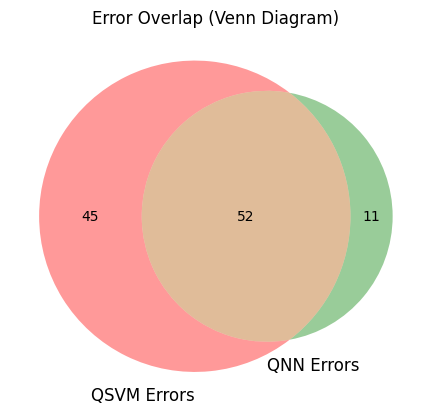

In [ ]:
from matplotlib_venn import venn2

venn2(
    subsets = (
        len(E_qsvm) - len(E_int),
        len(E_qnn) - len(E_int),
        len(E_int)
    ),
    set_labels = ("QSVM Errors", "QNN Errors")
)
plt.title("Error Overlap (Venn Diagram)")
plt.show()


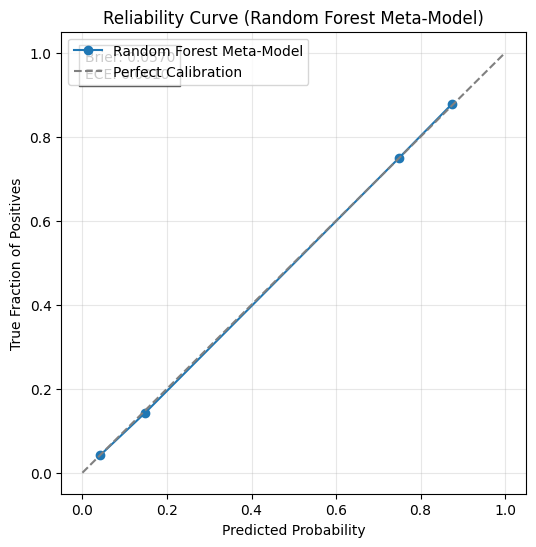

Brier Score: 0.0570
Expected Calibration Error (ECE): 0.0010


In [ ]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss
import matplotlib.pyplot as plt
import numpy as np

# --- Step 1: Predict probabilities on the same meta-data ---
meta_probs = meta_model_rf.predict_proba(X_meta)[:, 1]
meta_preds = meta_model_rf.predict(X_meta)
y_meta_test = y_test[:1000]  # for clarity

# --- Step 2: Compute reliability curve (15 bins) ---
prob_true, prob_pred = calibration_curve(y_meta_test, meta_probs, n_bins=15, strategy='uniform')

# --- Step 3: Compute Brier score ---
brier = brier_score_loss(y_meta_test, meta_probs)

# --- Step 4: Compute Expected Calibration Error (ECE) ---
def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0.0, 1.0, n_bins + 1)
    binids = np.digitize(y_prob, bins) - 1
    ece = 0.0
    for i in range(n_bins):
        bin_mask = binids == i
        if np.any(bin_mask):
            acc = np.mean(y_true[bin_mask])
            conf = np.mean(y_prob[bin_mask])
            ece += np.abs(acc - conf) * np.mean(bin_mask)
    return ece

ece = compute_ece(y_meta_test, meta_probs, n_bins=15)

# --- Step 5: Plot Reliability Curve ---
plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker='o', label='Random Forest Meta-Model')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect Calibration')
plt.title('Reliability Curve (Random Forest Meta-Model)')
plt.xlabel('Predicted Probability')
plt.ylabel('True Fraction of Positives')
plt.legend(loc='upper left')
plt.grid(alpha=0.3)
plt.text(0.05, 0.9, f'Brier: {brier:.4f}\nECE: {ece:.4f}', transform=plt.gca().transAxes,
         bbox=dict(facecolor='white', alpha=0.7))
plt.show()

print(f"Brier Score: {brier:.4f}")
print(f"Expected Calibration Error (ECE): {ece:.4f}")


In [ ]:
import pennylane as qml
import numpy as np
import pandas as pd
from collections import Counter

def analyze_qnn_complexity(n_qubits, n_layers):
    """Analyze circuit structure (expanded) for QNN with StronglyEntanglingLayers."""
    
    dev = qml.device("default.qubit", wires=n_qubits)
    
    @qml.qnode(dev)
    def qnn_circuit(params):
        qml.templates.StronglyEntanglingLayers(params, wires=range(n_qubits))
        return qml.expval(qml.PauliZ(0))
    
    # Random parameters for given configuration
    shape = qml.StronglyEntanglingLayers.shape(n_layers=n_layers, n_wires=n_qubits)
    params = np.random.random(shape)
    
    # ---- Build & expand the circuit to count internal gates ----
    tape = qnn_circuit.construct((params,), {})
    expanded_tape = tape.expand(depth=5)  # force full decomposition into native gates
    
    # Extract true operations after expansion
    ops = expanded_tape.operations
    gate_count = len(ops)
    gate_types = Counter([op.name for op in ops])
    
    # ---- Compute circuit depth in a version-safe way ----
    try:
        # Newer PennyLane (≥0.34)
        depth = qml.resource.circuit_depth(qml.tape.QuantumScript(ops, expanded_tape.measurements))
    except Exception:
        try:
            # Older API location
            depth = qml.transforms.circuit_depth(qml.tape.QuantumScript(ops, expanded_tape.measurements))
        except Exception:
            # Fallback: approximate depth = number of layers * 2 (safe heuristic)
            depth = n_layers * 2
    
    return {
        "Qubits": n_qubits,
        "Layers": n_layers,
        "Gates": gate_count,
        "Depth": depth,
        "Gate_Types": dict(gate_types)
    }

# --- Scalability test ---
results = []
for n_qubits in [1,2,3,4,5,6,7,8,9,10,11,12,13]:
    for n_layers in [1, 2, 3, 4, 5, 6, 7]:
        stats = analyze_qnn_complexity(n_qubits, n_layers)
        results.append(stats)
        print(f"Qubits={n_qubits}, Layers={n_layers} → Depth={stats['Depth']}, Gates={stats['Gates']}")

scalability_df = pd.DataFrame(results)
display(scalability_df)


Qubits=1, Layers=1 → Depth=2, Gates=3
Qubits=1, Layers=2 → Depth=4, Gates=6
Qubits=1, Layers=3 → Depth=6, Gates=9
Qubits=1, Layers=4 → Depth=8, Gates=12
Qubits=1, Layers=5 → Depth=10, Gates=15
Qubits=1, Layers=6 → Depth=12, Gates=18
Qubits=1, Layers=7 → Depth=14, Gates=21
Qubits=2, Layers=1 → Depth=2, Gates=8
Qubits=2, Layers=2 → Depth=4, Gates=16
Qubits=2, Layers=3 → Depth=6, Gates=24
Qubits=2, Layers=4 → Depth=8, Gates=32
Qubits=2, Layers=5 → Depth=10, Gates=40
Qubits=2, Layers=6 → Depth=12, Gates=48
Qubits=2, Layers=7 → Depth=14, Gates=56
Qubits=3, Layers=1 → Depth=2, Gates=12
Qubits=3, Layers=2 → Depth=4, Gates=24
Qubits=3, Layers=3 → Depth=6, Gates=36
Qubits=3, Layers=4 → Depth=8, Gates=48
Qubits=3, Layers=5 → Depth=10, Gates=60
Qubits=3, Layers=6 → Depth=12, Gates=72
Qubits=3, Layers=7 → Depth=14, Gates=84
Qubits=4, Layers=1 → Depth=2, Gates=16
Qubits=4, Layers=2 → Depth=4, Gates=32
Qubits=4, Layers=3 → Depth=6, Gates=48
Qubits=4, Layers=4 → Depth=8, Gates=64
Qubits=4, Layers=5 →

,Qubits,Layers,Gates,Depth,Gate_Types
0,1,1,3,2,"{'RZ': 2, 'RY': 1}"
1,1,2,6,4,"{'RZ': 4, 'RY': 2}"
2,1,3,9,6,"{'RZ': 6, 'RY': 3}"
3,1,4,12,8,"{'RZ': 8, 'RY': 4}"
4,1,5,15,10,"{'RZ': 10, 'RY': 5}"
...,...,...,...,...,...
86,13,3,156,6,"{'RZ': 78, 'RY': 39, 'CNOT': 39}"
87,13,4,208,8,"{'RZ': 104, 'RY': 52, 'CNOT': 52}"
88,13,5,260,10,"{'RZ': 130, 'RY': 65, 'CNOT': 65}"
89,13,6,312,12,"{'RZ': 156, 'RY': 78, 'CNOT': 78}"
